# Kings and courts in European eyes
### An embeddings lab on seventeenth-century accounts of Asian courts

**Course:** European Imperialism in Asia, 1450–1850 (Online) · **Level:** upper-year undergraduate / MA · **Time:** 90 minutes (core stages 1–6); optional stages 7–8 for a second session

Between 1608 and 1698 English readers could buy accounts of the Mughal, Safavid, Qing, Ayutthaya, Tokugawa and Kandyan courts written by ambassadors, merchants, a physician, Jesuits and a captive. Many were translated from Dutch, French, German, Italian or Portuguese. Historians have argued about whether such texts described distinct political cultures or fitted every Asian court into one European template: magnificence, prostration, seclusion and despotic power over life and property. See Joan-Pau Rubiés, "Oriental Despotism and European Orientalism: Botero to Montesquieu", *Journal of Early Modern History* 9 (2005), and Sanjay Subrahmanyam, *Courtly Encounters: Translating Courtliness and Violence in Early Modern Eurasia* (2012).

**Research question.** *Do these accounts represent Asian courts in court-specific ways, or in a shared vocabulary? And when passages resemble each other, is that because of the court described or because of who wrote, translated and printed the text?*

**Method.** Each passage of about 140 words has been turned into a vector by a sentence-embedding model, so that passages with similar content lie close together. The vectors are a way of **finding** passages to read, not a substitute for reading them. Every numerical result in this notebook ends in close reading.

**What you hand in:** answers Q1–Q6 (Q7–Q8 if you do the optional stages) and the 400-word memo in Stage 9.

| Stage | Task | Minutes |
|---|---|---|
| 1 | The sources | 5 |
| 2 | From book to passage | 15 |
| 3 | What a vector notices | 15 |
| 4 | The map | 10 |
| 5 | Court or author? | 15 |
| 6 | Clusters and close reading | 25 |
| 7 | *(optional)* Themes across courts | – |
| 8 | *(optional)* Does the result survive? | – |
| 9 | Memo | 5 in class |

Run each cell in order (Shift+Enter). You do not need to write code; you may change any argument marked **`# try:`**. All vectors are precomputed, so the notebook runs offline. Only Stage 7's optional custom query downloads a model.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import embassylab as el
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)
df = el.load_passages()          # the analysis corpus: passages about rulers and courts
X = el.load_vectors(model="minilm", variant="norm")   # 2,388 x 384 vectors, normalised spelling
print(df.shape, X.shape)

(2388, 23) (2388, 384)


## Stage 1 · The sources

The corpus has 24 **source units**. A unit is one author's account inside one printed book. Samuel Purchas's *Pilgrimes* (1625) prints abridgements of Hawkins, Finch, Roe, Coryat and Saris; the 1669 Olearius also prints Mandelslo; Tavernier is split by the court his books describe. All texts are EEBO-TCP transcriptions of the English printings.

In [2]:
src = pd.read_csv("data/sources.csv")
src[["unit", "author", "observer", "orig_lang", "translator", "pub", "visit", "role"]].fillna("")

,unit,author,observer,orig_lang,translator,pub,visit,role
0,roe,Thomas Roe,English,English,,1625,1615-1619,Crown ambassador (EIC-funded)
1,hawkins,William Hawkins,English,English,,1625,1608-1611,EIC envoy / merchant
2,finch,William Finch,English,English,,1625,1608-1611,EIC merchant
3,coryat,Thomas Coryat,English,English,,1625,1615-1617,private traveller
4,terry,Edward Terry,English,English,,1655,1616-1619,chaplain to Roe's embassy
5,bernier,François Bernier,French,French,Henry Oldenburg,1676,1656-1668,physician resident at court
6,tavernier_india,Jean-Baptiste Tavernier,French,French,John Phillips,1677,1640-1667,jewel merchant
7,mandelslo,Johann Albrecht von Mandelslo,German,German,John Davies,1669,1638-1639,gentleman attached to the Holstein embassy
8,herbert,Thomas Herbert,English,English,,1634,1627-1629,member of Cotton's embassy
9,olearius,Adam Olearius,German,German,John Davies,1669,1633-1639,secretary of the Holstein embassy


In [3]:
pd.crosstab(df.author, df.court).loc[:, lambda t: t.sum() >= 20]

court,Caucasus,Deccan,Kandy,Mughal,Muscovy,Ottoman,Pegu,Qing,Safavid,Siam,South India,Tokugawa
author,,,,,,,,,,,,
Adam Brand,0,0,0,0,6,0,0,16,0,0,0,0
Adam Olearius,0,0,0,3,95,0,0,0,104,0,0,0
Alexandre de Chaumont,0,0,0,0,0,0,0,0,0,65,0,0
Arnoldus Montanus / Olfert Dapper,0,0,0,0,0,0,0,429,0,0,0,0
Edward Terry,0,0,0,88,0,0,0,0,0,0,0,0
Fernão Mendes Pinto,0,0,0,0,0,1,35,25,1,12,0,2
François Bernier,0,0,0,97,0,0,0,0,0,0,0,0
François Caron,0,0,0,0,0,0,0,0,0,0,0,47
Jean Chardin,28,0,1,1,0,36,0,1,119,0,0,0


**Question 1.** Choose two sources whose authors held different positions (an ambassador, a merchant, a physician resident at court, a captive, a Jesuit). Before looking at any results, predict one way the author's position shapes what he could observe of the ruler and the court.

> **Your answer (Q1):**
>
> _Write here._

## Stage 2 · From book to passage

The corpus was built by `scripts/build_corpus.py` in five steps. Each step is a decision you should be able to defend.

1. **Read** the TEI-XML transcription and keep the body text (no title pages, prefaces, indexes or marginal notes), recording the printed page and the chapter heading of every paragraph.
2. **Select** each author's portion of the book by its chapter headings.
3. **Segment** into passages of 90–170 words that never cross a chapter boundary.
4. **Attribute a court.** For an account written at one court (Roe, Bernier, Nieuhof, Chaumont, Knox...) every passage is assigned to that court. For travellers who crossed several (Tavernier, Olearius, Chardin, Pinto, della Valle...) a gazetteer of ruler titles, capitals and court place-names in period spellings decides, using the passage and its neighbours.
5. **Filter** for passages about rulers and courts: at least two words such as *king, emperor, court, audience, throne, palace, ambassador*, and a minimum density of related vocabulary (*nobles, eunuchs, presents, ceremony, prostrate, tribute...*).

Of 20,324 passages in the selected portions, 2,388 pass step 5.

In [4]:
el.show(df, "roe-0052", variant="text")        # the transcription as printed (long s already resolved)
print()
el.show(df, "roe-0052", variant="text_norm")   # after light spelling normalisation (Stage 8 tests its effect)

roe-0052 | Thomas Roe | Mughal | p. 542 | CHAP. XVI. Obseruations collected out of the Iournall of Sir THOMAS ROE, Knight, Lord Embassadour from His MAIESTIE of Great Britaine, to the Great Mogol: Of ma > §. II. His iourney to the Court, and 
At the Durbar I was led right before him: at the entrance of an outward raile, where met mee two
principall Noble Slaues to conduct me nearer. I had required before my going, leaue to vse the
customes of my Countrey, which was freely granted, so that I would performe them punctually. When I
entered within the first raile, I made a reuerence; entring in the inward raile, another; and when I
came vnder the King, a third. The place is a great Court, whither resort all sorts of people. The
King sits in a little Gallery ouer-head; Ambassadors, the great men and strangers of quality within
the inner-most raile vnder him, raised from the ground, couered with Canopies of Veluet and Silke;
vnder-foote laid with good Carpets: the meaner men representing Gen

In [5]:
pd.crosstab(df.court, df.court_basis, margins=True).sort_values("All", ascending=False)

court_basis,gazetteer,unit (single-court account),All
court,,,
All,909,1479,2388
Qing,49,776,825
Mughal,118,417,535
Safavid,422,0,422
Kandy,8,105,113
Muscovy,102,0,102
Siam,24,77,101
Tokugawa,3,73,76
Ottoman,40,31,71


**Audit.** Steps 4 and 5 are automatic, so they make mistakes. Draw ten passages (set `seed` to your student number) and judge each: *is it about a ruler or court?* (yes / partly / no) and *is the court right?* Then compare with the instructor's audit of 40 passages.

In [6]:
seed = 7                          # try: your student number
for pid in df.sample(10, random_state=seed).pid:
    el.show(df, pid); print("-" * 100)

hawkins-0107 | William Hawkins | Mughal | p. 220 | CHAP. VII. Captaine WILLIAM HAVVKINS, his Relations of the Occurrents which happened in the time of his residence in India, in the County of the Great MOGOLL, a > § IIII. A briefe Discourse of the str
Now, when the King heard that the dish was broken, he was in a great rage, commanding him to be
brought before him, and to be beaten by two men, with two great whips made of cords: and after that
he had received one hundred and twenty of these lashes, he commanded his Porters, who be appointed
for that purpose, to beate him with their small Cudgels, till a great many of them were broken: at
the least twenty men were beating of him, till the poore man was thought to be dead, and then he was
haled out by the heeles, and commaunded to prison. The next day the King demaunded whether he was
living, answer was made, that he was: whereupon, he commanded him to be carried unto perpetual
prison. But the Kings Son being his friend, freed him of tha

In [7]:
audit = pd.read_csv("data/audit_sample.csv")
print(audit.about_court.value_counts().to_string(), "\n")
print(pd.crosstab(audit.court_basis, audit.court_correct).to_string())
audit[audit.court_correct == "no"][["pid", "court", "note"]]

about_court
yes        31
partial     6
no          3 

court_correct                no  yes
court_basis                         
gazetteer                     3   12
unit (single-court account)   0   23


,pid,court,note
12,olearius-1542,Muscovy,Safavid shah hunting with women and eunuchs; attributed to Muscovy by the ga...
33,dellavalle-0201,Safavid,Mughal palace at Ahmedabad; attributed to Safavid by the gazetteer
35,olearius-2175,Muscovy,Muscovite envoy's feast at a Safavid khan's palace; attributed to Muscovy


**Question 2.** Report your ten judgements as two counts. Which step (4 or 5) produced the errors you found, and what kind of passage does each step get wrong? Would these errors make courts look *more* or *less* alike?

> **Your answer (Q2):**
>
> _Write here._

## Stage 3 · What a vector notices

An embedding model maps each passage to 384 numbers. **Cosine similarity** between two vectors runs from about 0 (unrelated) to 1 (near-identical in content). In this corpus, a typical pair of passages scores about 0.33.

Start from Thomas Roe's first audience with Jahangir at the durbar in Ajmer (1616) and find its nearest neighbours. Passages within three positions of the anchor *in the same book* are skipped, because they are simply the continuation of the same scene.

In [8]:
anchor = "roe-0052"               # try: "chaumont-0047" (Siam), "nieuhof-0454" (Qing), "knox-0582" (Kandy)
el.show(df, anchor)
el.neighbours(X, df, anchor, k=8)

roe-0052 | Thomas Roe | Mughal | p. 542 | CHAP. XVI. Obseruations collected out of the Iournall of Sir THOMAS ROE, Knight, Lord Embassadour from His MAIESTIE of Great Britaine, to the Great Mogol: Of ma > §. II. His iourney to the Court, and 
At the Durbar I was led right before him: at the entrance of an outward raile, where met me two
principal Noble Slaves to conduct me nearer. I had required before my going, leave to use the
customes of my Country, which was freely granted, so that I would performe them punctually. When I
entered within the first raile, I made a reverence; entring in the inward raile, another; and when I
came under the King, a third. The place is a great Court, whither resort all sorts of people. The
King sits in a little Gallery over-head; Ambassadors, the great men and strangers of quality within
the inner-most raile under him, raised from the ground, covered with Canopies of Veluet and Silke;
under-foote laid with good Carpets: the meaner men representing Gentry

,similarity,pid,author,court,page
0,0.657,roe-0378,Thomas Roe,Mughal,583
1,0.654,roe-0062,Thomas Roe,Mughal,543
2,0.641,roe-0172,Thomas Roe,Mughal,557
3,0.624,tavernier_india-0164,Jean-Baptiste Tavernier,Mughal,46
4,0.620,roe-0194,Thomas Roe,Mughal,559
5,0.620,bernier-0474,François Bernier,Mughal,176
6,0.617,hawkins-0003,William Hawkins,Mughal,206
7,0.615,roe-0042,Thomas Roe,Mughal,540


In [9]:
nb_ = el.neighbours(X, df, anchor, k=3)
for pid in nb_.pid:
    print(); el.show(df, pid)


roe-0378 | Thomas Roe | Mughal | p. 583 | CHAP. XVI. Obseruations collected out of the Iournall of Sir THOMAS ROE, Knight, Lord Embassadour from His MAIESTIE of Great Britaine, to the Great Mogol: Of ma > §. X. The seuerall Kingdomes and Prou
I came into a Court full of base people, and at a raile which shut them out right against the King,
I was stayed in his sight to demand audience (only a ceremony) so he sent his principal Officers to
bring me up: he sate in a place like a Theatre above, where the King sits in a Play, and I was
conducted foure steps up, just under him, like a stage, all on Carpets; my self and all his great
men were Actors, the common-people below gazing on. He prevented me with speech, calling the King
his Brother, and that I must consequently be welcome: for the barbarous custome of kneeling and
knocking the ground with the head (which he never pardoned, neither the Turkes nor Persian
Ambassadors) he required not, but at my first motion granted me all liberty of

**Question 3.** Read the anchor and its three nearest neighbours. What do they share: the *situation* (an audience), the *court*, the *author*, a *vocabulary* (reverence, presence, rail)? Name one thing a historian would consider essential to the anchor that the neighbours do **not** share.

> **Your answer (Q3):**
>
> _Write here._

## Stage 4 · The map

UMAP projects the 384-dimensional vectors onto two dimensions while trying to keep near neighbours near. Distances **between** distant groups on the map are not meaningful; local neighbourhoods are. Each panel shows one court in blue over the whole corpus in grey.

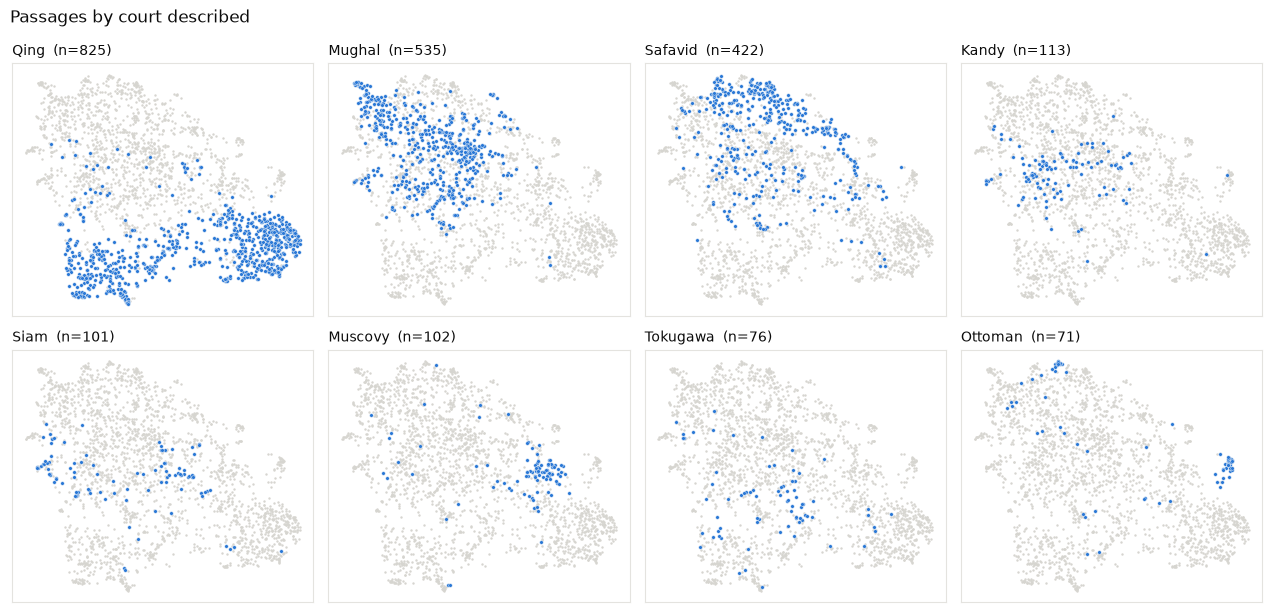

In [10]:
xy = el.load_map("minilm", "norm")[["x", "y"]].to_numpy()
el.facet_map(xy, df, by="court", groups=el.MAIN_COURTS, title="Passages by court described");

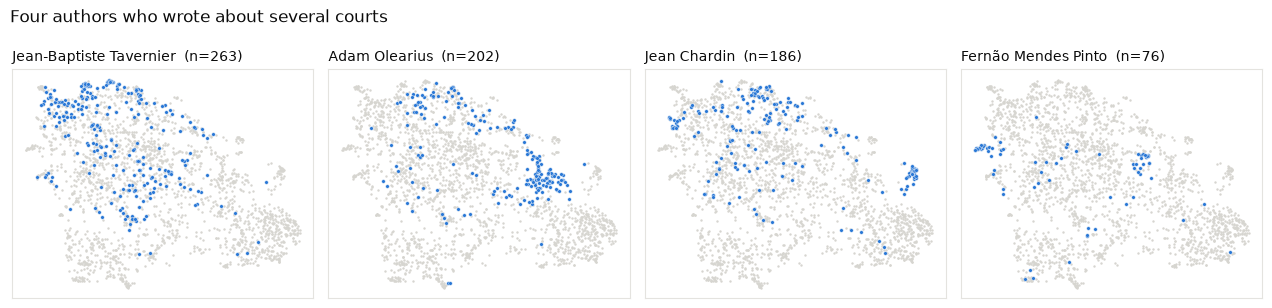

In [11]:
authors = ["Jean-Baptiste Tavernier", "Adam Olearius", "Jean Chardin", "Fernão Mendes Pinto"]   # try: other authors
el.facet_map(xy, df, by="author", groups=authors, title="Four authors who wrote about several courts");

**Question 4.** Compare the court panels with the author panels. Does Tavernier's material sit with the courts he describes, or together as 'Tavernier'? What would you need to check before trusting that impression?

> **Your answer (Q4):**
>
> _Write here._

## Stage 5 · Court or author?

Three tests of the same question, from simplest to most controlled. Each one ignores pairs of passages that are close together in the same book.

**(a) Nearest-neighbour agreement.** For every passage, what share of its 10 nearest neighbours has the same label (same court, same author...)? *Chance* is the share expected if neighbours were random; *lift* is agreement divided by chance.

In [12]:
pd.DataFrame([el.knn_agreement(X, df, lab, k=10) for lab in ["court", "author", "translator", "observer", "era"]]).set_index("label")

,groups,agreement,chance,lift
label,,,,
court,12,0.639,0.209,3.05
author,22,0.436,0.083,5.24
translator,9,0.576,0.177,3.26
observer,6,0.633,0.246,2.57
era,2,0.858,0.769,1.12


Court and author are entangled: most authors describe one court. **(b) The crossed test** uses only the authors who describe two or more courts. For each of their passages it compares mean similarity to (i) the same author on another court, (ii) other authors on the same court, and (iii) other authors on other courts (the baseline).

same_author_other_court  other_author_same_court  other_author_other_court
author                        court                                                                              
Adam Olearius                 Safavid                    0.361                    0.378                     0.333
Fernão Mendes Pinto           Qing                       0.391                    0.338                     0.351
                              Siam                       0.407                    0.390                     0.359
Jean Chardin                  Ottoman                    0.353                    0.357                     0.351
                              Safavid                    0.367                    0.387                     0.354
Jean-Baptiste Tavernier       Mughal                     0.361                    0.368                     0.323
                              Ottoman                    0.348                    0.357                     0.331
                              Safavid                    0.361                    0.382                     0.333
Johann Albrecht von Mandelslo Mughal                     0.356                    0.372                     0.317
                              Safavid                    0.365                    0.391                     0.341
                              Siam                       0.335                    0.382                     0.315
Pietro della Valle            Safavid                    0.343                    0.368                     0.316
Thomas Herbert                Mughal                     0.397                    0.392                     0.321
                              Safavid                    0.397                    0.387                     0.343

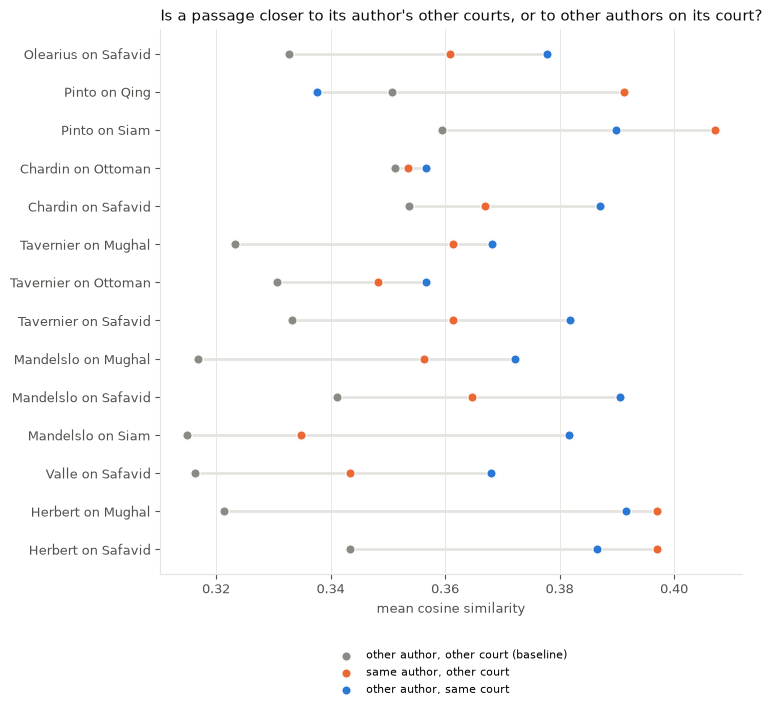

In [13]:
crossed = el.crossed_test(X, df, min_n=8)
el.crossed_plot(crossed)
crossed.groupby(["author", "court"]).mean(numeric_only=True).round(3)

**(c) Regression over all pairs.** For every pair of passages (about 2.8 million), cosine similarity is regressed on whether they share a court, an author and a named translator. Each coefficient is the average change in similarity from sharing that attribute *with the others held fixed*. This separates court from author only to the extent that the corpus contains authors who cross courts and courts described by several authors.

,coefficient,share_of_pairs
baseline (nothing shared),0.3323,1.0000
same court,0.0422,0.2085
same author,0.0352,0.0820
same translator,0.0106,0.1299


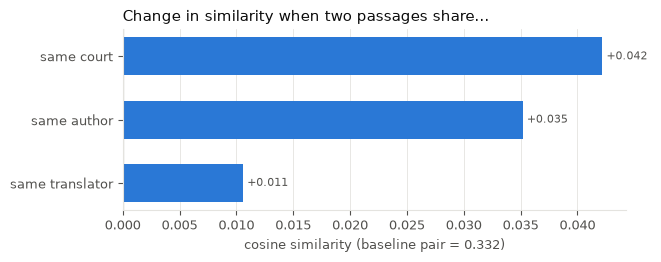

In [14]:
tab = el.pair_regression(X, df, factors=("court", "author", "translator"))   # try: add "era"
el.coef_plot(tab)
tab

**Question 5.** In two or three sentences: does the court described or the writer matter more for how similar two passages are? Point to the specific number in (b) or (c) that supports your answer, and name one author for whom the answer is different.

> **Your answer (Q5):**
>
> _Write here._

## Stage 6 · Clusters and close reading

k-means divides the vectors into 10 groups. For each cluster the table gives its size, its most common courts and authors, its **distinctive words** (frequent in this cluster, rare in the others), and the three passages closest to its centre.

A cluster is a hypothesis about a shared *kind* of passage. Your job is to name it by reading, then test the name.

In [15]:
labels = el.kmeans(X, k=10, seed=0)             # try: k=6 or k=14
df["cluster"] = labels
profile = el.cluster_profile(df, labels, X)
profile[["passages", "courts", "authors", "n_authors", "terms"]]

,passages,courts,authors,n_authors,terms
cluster,,,,,
0,238,"Mughal 51%, Qing 11%, Siam 10%","Roe 28%, Hawkins 12%, Terry 8%",18,"king, majesty, court, sent, letter, kings, prince, give, present, told, amba..."
1,312,"Mughal 34%, Safavid 26%, Kandy 16%","Tavernier 18%, Knox 16%, Roe 15%",20,"king, kings, prince, sent, court, man, people, men, put, father, commanded, ..."
2,184,"Qing 49%, Safavid 16%, Muscovy 12%","Montanus 26%, Olearius 19%, Nieuhof 17%",17,"emperor, ambassadors, king, ambassador, gold, court, silver, presents, went,..."
3,193,"Safavid 75%, Mughal 16%, Muscovy 3%","Tavernier 24%, Chardin 23%, Olearius 20%",14,"king, persia, kings, court, persian, persians, prince, ambassador, son, sent..."
4,200,"Mughal 30%, Qing 16%, Safavid 12%","Tavernier 20%, Knox 10%, Roe 8%",21,"king, court, palace, elephants, city, kings, men, gold, little, gate, throne..."
5,295,"Qing 96%, Siam 1%, Tokugawa 1%","Montanus 73%, Nieuhof 20%, Brand 2%",11,"ambassador, peking, emperor, presents, ambassadors, general, batavia, answer..."
6,279,"Qing 32%, Safavid 19%, Muscovy 19%","Olearius 27%, Montanus 24%, Chardin 16%",17,"ambassador, ambassadors, king, sent, answer, vizier, highness, duke, court, ..."
7,245,"Mughal 49%, Safavid 14%, Ottoman 6%","Tavernier 21%, Bernier 17%, Chardin 10%",20,"king, sultan, son, emir, prince, kings, father, kingdom, court, aureng, dwel..."
8,280,"Qing 95%, Tokugawa 2%, Safavid 1%","Comte 32%, Montanus 31%, Nieuhof 30%",12,"emperor, court, call, city, china, peking, chinese, emperors, king, empire, ..."


In [16]:
c = 3                                           # try: each cluster in turn
print(profile.loc[c, "terms"], "\n")
for pid in profile.loc[c, "representative"].split(", "):
    el.show(df, pid); print("-" * 100)

king, persia, kings, court, persian, persians, prince, ambassador, son, sent, call, take 

chardin-0913 | Jean Chardin | Safavid | p. 341 | THE TRAVELS OF Sir John Chardin INTO PERSIA, Through the Black-Sea, and the Country of Colchis.
The 6. The Prince's Treasurer gave me a Dinner, and the Kings Lieutenant of the Fortress was at it.
He is a Native of Dag-Estaan. Which is a Mountainous Country to the North-East of the Caspian Sea,
and bordering upon Muscovy. So that I took great delight to hear him repeat several particulars of
the Customes and Manners of his Country. The King of Persia is acknowledg'd there as Soveraign Lord;
but he is not absolute Master of it: nor are the People that inhabit it always subject to his
Commands. And the Court winks at their Disobediences; it being a difficult thing to reduce 'em, by
reason of the Roughness and Height of the Mountaines. They are a Savage sort of People, and the most
barbarous of all the East: and I take 'em to be some Remainders of the 

Now test your label on passages that are *not* at the centre of the cluster:

In [17]:
for pid in df[df.cluster == c].sample(5, random_state=1).pid:     # try: another random_state
    el.show(df, pid); print("-" * 100)

herbert-0331 | Thomas Herbert | Safavid | p. 108 | Mount Taurus.
In this place, five and twenty years agoe ruled a King Meleck Bahaman by name, who commanded like
another Pluto, through these Hils and Dales in Taurus, a Prince though confined to small limits, and
forced with great cost and care to maintaine his Royalties against the Tartar and Persian, his great
and quarrelsome Neighbours, yet such was his good fortune, his policy, valour and love unto his
subjects, that though often inuaded and by many Princes, he stood secure, and lived to see the r ine
and downfal of many, his late enemies. His only ayme tending to preserue, what his Predecessours had
made him heire to, and that his gray haires might go in peace to an eternal Dormitory. Thus thought
Bahaman, and added his endevours to preserue his thoughts. But Abbas the Persian and victorious
King, whose resolutions were all for conquest, whose doings were ever turbulent, and whose aspiring
conceits most wonderful:
----------------

**Question 6.** Choose **two** clusters: one dominated by a single court or author, one that mixes courts. For each: (a) give it a label in five words or fewer; (b) say how many of the five random members fit the label; (c) quote a phrase from a passage (with its id and page) that shows what the cluster has in common. For the mixed cluster: does it show a shared European way of describing kings, or a shared situation (audience, gift-giving, war) that any account would describe in similar words?

> **Your answer (Q6):**
>
> _Write here._

## Stage 7 · *(optional)* Themes across courts

A **probe** is a short sentence that states a theme. The ten probes below are taken from debates about European representations of Asian monarchy. For each probe and court, the heat map shows how over-represented that court's passages are among the 5% of the corpus most similar to the probe (1.0 = as expected from its size; 2.0 = twice as many as expected).

In [18]:
names, P = el.probe_vectors("minilm")
pd.Series(el.PROBES).to_frame("probe sentence")

,probe sentence
prostration,The ambassador was ordered to kneel and knock his head against the ground be...
throne,"The king sat upon a throne of massy gold set with diamonds, rubies and great..."
royal_property,"All the land of the kingdom belongs to the king, and no subject has any prop..."
punishment,For a small fault the king commanded the man to be cruelly put to death in h...
gifts,The presents brought by the ambassador were carried in and shown to the king...
seclusion,The king's wives and concubines are kept shut up in the palace and guarded b...
drinking,The king drank wine with the ambassador and made merry with him late into th...
officials,The empire is governed by councils and tribunals of officials who examine ev...
precedence,There was a long dispute about where the ambassador should sit and whether h...
royal_religion,The king is very devout and spends much time with his priests in the temples.


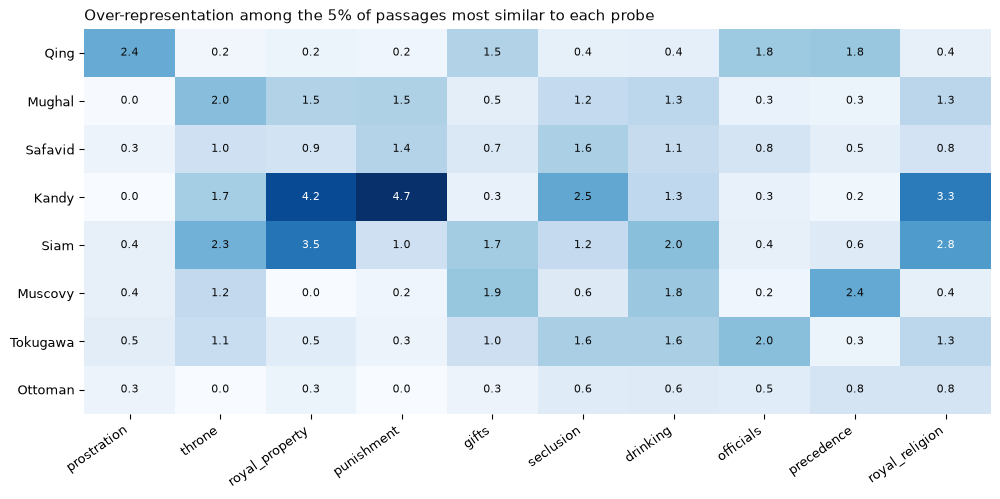

In [19]:
tab = pd.DataFrame({n: el.probe_by_court(X, df, P[i], courts=el.MAIN_COURTS)["over_representation"]
                    for i, n in enumerate(names)}).loc[el.MAIN_COURTS]
el.heatmap(tab, "Over-representation among the 5% of passages most similar to each probe");

In [20]:
probe = "royal_property"                      # try: "prostration", "seclusion", "officials"...
q = P[names.index(probe)]
top = el.top_passages(X, df, q, n=6)
display(top)
for pid in top.pid[:3]:
    el.show(df, pid); print("-" * 100)

,pid,author,court,page,similarity
0,bernier-0450,François Bernier,Mughal,157,0.589
1,mandelslo-0660,Johann Albrecht von Mandelslo,Siam,99,0.560
2,nieuhof-0559,Johan Nieuhof,Qing,142,0.555
3,knox-0188,Robert Knox,Kandy,43,0.535
4,terry-0570,Edward Terry,Mughal,313,0.524
5,olearius-1865,Adam Olearius,Safavid,255,0.523


bernier-0450 | François Bernier | Mughal | p. 157 | A Letter to the Lord COLBERT, of the Extent of Indostan; the Circulation of Gold and Silver, coming at length to be swallowed up, there, as in an Abyss; the Ric
the King is the sole proprietor of all the Lands of the Kingdom; whence it necessarily follows, that
a whole Metropolitan City, such as Dehly and Agra, liveth of almost nothing but of the Souldiery,
and is consequently obliged to follow the King when he taketh the Field; those Towns being nothing
less than Paris, but indeed no otherwise governed than a Camp of Armies a little better and more
conveniently lodged than in the open Field.
----------------------------------------------------------------------------------------------------
mandelslo-0660 | Johann Albrecht von Mandelslo | Siam | p. 99 | MANDELSLO's TRAVELS INTO THE INDIES.
The King of Siam that now reigns, and who amongst his other Titles, takes that of Precau Salcu, that
is, Sacred Member of God, holds the Crown fro

A probe finds passages that *resemble* its sentence, which is not the same as passages that *mention* its subject. Compare with a plain word search:

In [21]:
word = "prostrat"                             # try: "kneel", "knock", "eunuch", "tribute"
hits = df[df.text_norm.str.contains(word, case=False)]
print(len(hits), "passages contain", repr(word))
hits.groupby(["court", "author"]).size().sort_values(ascending=False).head(10)

27 passages contain 'prostrat'


court    author                           
Siam     Alexandre de Chaumont                9
Qing     Louis Le Comte                       5
Mughal   Thomas Roe                           2
Siam     Fernão Mendes Pinto                  2
Safavid  Jean Chardin                         2
Qing     Arnoldus Montanus / Olfert Dapper    1
Mughal   Jean-Baptiste Tavernier              1
Pegu     Fernão Mendes Pinto                  1
Safavid  Adam Olearius                        1
Qing     Fernão Mendes Pinto                  1
dtype: int64

To write your own probe, install `sentence-transformers` (`pip install sentence-transformers`); the first run downloads the MiniLM model, about 90 MB:
```python
q = el.embed_queries(["The ambassador's letter from his king was received with great ceremony."])[0]
el.top_passages(X, df, q, n=8)
```
**Question 7.** Choose one probe where one or two courts stand out. Read the top six passages, and compare them with a word search for the probe's key term. Is the result about how Europeans *represented* that court, about the *genre* of the source (a narrative of audiences, a treatise on government), or about the words the probe happens to use? Reword the probe once and report whether the ranking of courts changes.

> **Your answer (Q7):**
>
> _Write here._

## Stage 8 · *(optional)* Does the result survive?

Two choices were built into everything above: **spelling normalisation** and the **model**. Rerun the main tests with raw spelling and with a second, larger model (BAAI/bge-base-en-v1.5, 768 dimensions).

In [22]:
rows = []
for model, variant in [("minilm", "norm"), ("minilm", "raw"), ("bge", "norm"), ("bge", "raw")]:
    V = el.load_vectors(model=model, variant=variant)
    r = {f"{lab} lift": el.knn_agreement(V, df, lab)["lift"] for lab in ["court", "author", "era"]}
    reg = el.pair_regression(V, df)["coefficient"]
    r.update({"baseline": reg.iloc[0], "same court": reg["same court"], "same author": reg["same author"],
              "court / author": reg["same court"] / reg["same author"]})
    rows.append(dict(model=model, spelling=variant, **r))
pd.DataFrame(rows).set_index(["model", "spelling"]).round(3)

court lift  author lift  era lift  baseline  same court  same author  court / author
model  spelling                                                                                      
minilm norm            3.05         5.24      1.12     0.332       0.042        0.035           1.199
       raw             3.11         5.47      1.17     0.333       0.044        0.038           1.141
bge    norm            2.89         4.84      1.11     0.613       0.020        0.018           1.086
       raw             2.93         4.91      1.13     0.614       0.021        0.020           1.060

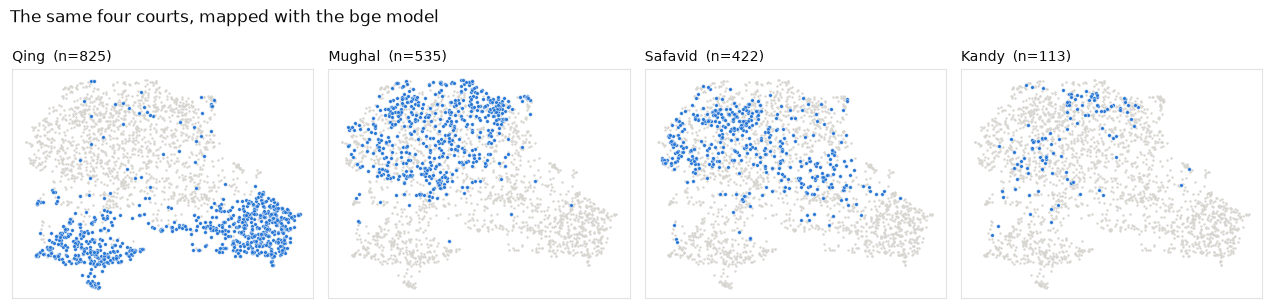

In [23]:
xb = el.load_map("bge", "norm")[["x", "y"]].to_numpy()
el.facet_map(xb, df, by="court", groups=el.MAIN_COURTS[:4], title="The same four courts, mapped with the bge model");

In [24]:
# How far do the two models agree on each passage's nearest neighbours?
B = el.load_vectors(model="bge", variant="norm")
def nn(V, k=10):
    S = V @ V.T; np.fill_diagonal(S, -np.inf); S[el.near_mask(df)] = -np.inf
    return np.argsort(-S, axis=1)[:, :k]
a, b = nn(X), nn(B)
overlap = np.mean([len(set(a[i]) & set(b[i])) / 10 for i in range(len(df))])
print(f"Average overlap of the 10 nearest neighbours, MiniLM vs bge: {overlap:.2f}")

Average overlap of the 10 nearest neighbours, MiniLM vs bge: 0.29


**Question 8.** Which conclusions from Stages 5–6 hold under every combination, and which depend on the model or on spelling? Why can the coefficients of the two models not be compared directly, while their ratio can? Look at the *era lift*: what does normalising spelling remove?

> **Your answer (Q8):**
>
> _Write here._

## Stage 9 · Memo (400 words)

Answer the research question for a reader who has not seen this notebook. Your memo must:

1. make **one** claim about how these accounts represent Asian courts: court-specific, shared, or a specified mixture;
2. support it with **one quantitative result** from Stage 5, 6 or 7, stated with its number;
3. quote **three passages** (id, author, page) that show what the quantitative result corresponds to in the texts;
4. name **one** way the corpus or the method could produce your result artificially, and how you would check it.

---
**Sources:** Early English Books Online Text Creation Partnership (EEBO-TCP), Phase I texts, CC0. See `data/README.md` for the full list, the rules used to build the corpus, and its known errors. **Models:** sentence-transformers/all-MiniLM-L6-v2; BAAI/bge-base-en-v1.5. **Code:** `embassylab.py`, `scripts/`.

> **Your answer (memo):**
>
> _Write here._